# 5. Model CNN-LSTM

Rovnaké príznaky ResNet18 ako v notebooku 4, ale namiesto priemeru ich číta
**LSTM** (rekurentná sieť) **postupne, snímka po snímke**. LSTM si pri čítaní udržiava
skrytý stav; po poslednej snímke z neho lineárna vrstva určí triedu.

CNN sa netrénuje, trénuje sa iba LSTM nad uloženými príznakmi.

**Trénovanie** (`har/models.py`):
- 20 % filmov z trénovacích dát sa oddelí ako validačné dáta,
- po každej epoche sa zmeria strata na validačných dátach; model ponechá váhy z epochy
  s najnižšou validačnou stratou (**early stopping**),
- 1 vrstva LSTM so 128 neurónmi, dropout 0,5, váhy tried v stratovej funkcii.

Hodnotenie je rovnaké ako v notebooku 4.

In [1]:
import numpy as np
import pandas as pd
import torch

from har.config import INDEX_FILE
from har.evaluation import evaluate_lstm, plot_confusion, plot_history, save_predictions, summary

df = pd.read_csv(INDEX_FILE)
feats = np.load("features_resnet.npy")     # (klipy, 16, 512)
device = "cuda" if torch.cuda.is_available() else "cpu"

## Hodnotenie

In [2]:
pred, (history, best_epoch) = evaluate_lstm(feats, df, device)
save_predictions(pred, "cnn_lstm")
summary(pred, "CNN-LSTM")

,presnosť (accuracy),správne eat (recall),správne clap (recall)
CNN-LSTM,86 % ± 8 %,94 % ± 4 %,79 % ± 16 %


## Priebeh trénovania

Strata na trénovacích a validačných dátach v prvom delení.
Zvislá čiara označuje epochu, ktorej váhy model používa.

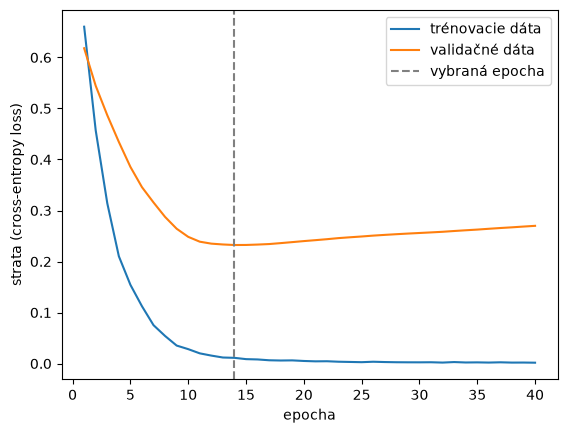

In [3]:
plot_history(history, best_epoch)

## Chyby modelu

Matica zámen (*confusion matrix*) zo všetkých 10 delení. Riadok = skutočná trieda,
stĺpec = predpoveď modelu.
- vľavo: počet testovacích klipov (súčet cez 10 delení, každý klip je v teste viackrát),
- vpravo: % klipov danej skutočnej triedy (súčet v riadku je 100 %).

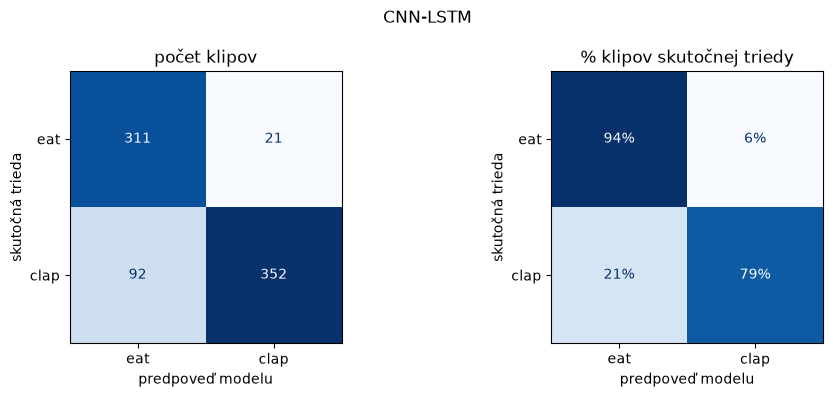

In [4]:
plot_confusion(pred, "CNN-LSTM")